# PREP_02 — Analisis Sentimen IndoBERT (X2)
## Tesis: Prediksi Volatilitas Return Saham Energi LQ45 — Ilda Nurida (ITS)
**Mesin:** IndoBERT-base-p2 fine-tuned (3 kelas) · **Output:** `skor_sentimen_harian.csv` (X2)
> Jalankan di **Google Colab (GPU)**. Sel A–D siapkan data · Sel E–I fine-tune & skor · Sel J–N tabel/grafik/export Bab 4.

## SEL A — Setup & Konfigurasi

In [1]:
# ════ CELL A : SETUP (FIXED & CLEAN) ════

!pip install -q transformers torch scikit-learn sentencepiece

import warnings
warnings.filterwarnings('ignore')

import re
import os
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from pathlib import Path

# =========================
# ROOT PATH (PATH UTAMA THESIS)
# =========================
ROOT = Path(
    r"E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026"
)

# =========================
# FOLDER DATASET
# =========================
DIR_FINAL = ROOT / "03_dataset" / "final"
DIR_PROCESSED = ROOT / "03_dataset" / "processed"

# =========================
# OUTPUT (FOLDER YANG SUDAH ADA)
# =========================
DIR_OUT = ROOT / "02_preprocessing" / "sentimen_indobert" / "output_sentimen 1"

# supaya cell lain gak error
DIR_TABLE = DIR_OUT
DIR_IMG = DIR_OUT

# =========================
# EMITEN ORDER
# =========================
URUTAN_EMITEN = ['ADRO','ADMR','ITMG','PTBA','MEDC','AKRA','PGAS']

# =========================
# DEVICE
# =========================
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# =========================
# FOLDER GAMBAR (TERPUSAT — dipakai SEL G, I, J, L)
# =========================
DIR_GAMBAR = DIR_OUT / "gambar"
for _d in [DIR_OUT, DIR_GAMBAR, DIR_PROCESSED]:
    _d.mkdir(parents=True, exist_ok=True)

print("Device:", DEVICE)
print("ROOT:", ROOT)
print("DIR_FINAL:", DIR_FINAL)
print("Output:", DIR_OUT)
print("Gambar:", DIR_GAMBAR)


[notice] A new release of pip available: 22.3 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Device: cpu
ROOT: E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026
DIR_FINAL: E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\final
Output: E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\02_preprocessing\sentimen_indobert\output_sentimen 1
Gambar: E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\02_preprocessing\sentimen_indobert\output_sentimen 1\gambar


## 📂 SEL B — Load Berita

In [2]:
# ════ SEL B : LOAD BERITA ════
PATH_BERITA = DIR_FINAL / 'berita_gabungan_semua_sumber_FINAL.csv'
# ⚠️ Pastikan file ini hasil GABUNG_BERITA_FINAL_v2 (dedup Link+Kode_Emiten,
#    5 sumber, ±9.300 artikel). Bila masih ±4.150 artikel, jalankan ulang
#    GABUNG_BERITA_FINAL_v2.ipynb terlebih dahulu.

# ── GUARD URUTAN EKSEKUSI ──────────────────────────────────────────────
# SEL K mengambil kalender hari bursa dari technical_features.csv. Bila
# PREP_01 v3 (periode 2022-01-01) belum dijalankan, kalender masih 746 hari
# dan fitur sentimen ikut terpotong ke April 2023 tanpa pesan error apa pun.
_p_tek = DIR_PROCESSED / 'technical_features.csv'
if _p_tek.exists():
    _n = pd.read_csv(_p_tek, usecols=['Date'])['Date'].nunique()
    if _n < 900:
        raise RuntimeError(
            f'STOP: technical_features.csv hanya {_n} hari bursa (harusnya ±1.040).\n'
            f'-> Jalankan PREP_01_technical_indicators_v3.ipynb dulu '
            f'(PERIODE_AWAL = 2022-01-01), baru ulangi notebook ini.')
    print(f'  ✅ Kalender teknikal: {_n} hari bursa — periode 2022 sudah aktif')
else:
    raise RuntimeError('technical_features.csv belum ada — jalankan PREP_01 v3 dulu.')
assert PATH_BERITA.exists(), f'File berita tidak ditemukan:\n{PATH_BERITA}'

df_berita = pd.read_csv(PATH_BERITA, encoding='utf-8-sig')
df_berita['Tanggal'] = pd.to_datetime(df_berita['Tanggal'], errors='coerce')
df_berita = df_berita.sort_values(['Kode_Emiten','Tanggal']).reset_index(drop=True)

def bersih_ringan(t):
    if not isinstance(t,str): return ''
    t = re.sub(r'http\S+|www\.\S+',' ',t)
    t = re.sub(r'\[Gambas.*?\]|Lihat juga Video.*',' ',t,flags=re.IGNORECASE)
    return re.sub(r'\s+',' ',t).strip()

df_berita['Teks'] = df_berita['Headline'].apply(bersih_ringan)
df_berita = df_berita[df_berita['Teks'].str.len()>0].reset_index(drop=True)
print(f'Total artikel: {len(df_berita):,} | {df_berita["Tanggal"].min().date()} -> {df_berita["Tanggal"].max().date()}')
print(df_berita['Kode_Emiten'].value_counts().to_string())

  ✅ Kalender teknikal: 1074 hari bursa — periode 2022 sudah aktif
Total artikel: 9,280 | 2022-01-01 -> 2026-06-30
Kode_Emiten
PGAS    2311
PTBA    1888
ADRO    1837
MEDC    1398
AKRA     830
ITMG     651
ADMR     365


## 🏷️ SEL C — Auto-label (untuk lembar anotasi)

In [3]:
# ════ SEL C : AUTO-LABEL (revisi) ════
KATA_POSITIF = {
 'naik','meningkat','tumbuh','menguat','melonjak','melesat','meroket','melejit',
 'terbang','rebound','rally','bullish','surplus','profit','keuntungan','rekor',
 'tertinggi','dividen','buyback','ekspansi','akuisisi','ipo','kontrak baru','optimis','pemulihan',
 'solid','cuan','top gainers','gainers','positif','cemerlang','sukses','raih',
 'menguntungkan','ekspor naik','produksi naik','harga batu bara naik','potensi cuan',
 # kata ambigu HARUS berupa frasa, bukan kata tunggal:
 'laba naik','laba melonjak','laba tumbuh','laba meningkat','laba melesat','catat laba',
 'untung besar','saham diborong','banyak dibeli','laba bersih naik','laba bersih tumbuh',
 'laba bersih melonjak','pendapatan naik','pendapatan tumbuh',
}

KATA_NEGATIF = {
 'turun','menurun','melemah','anjlok','ambles','jeblok','ambruk','terjun','jatuh',
 'merosot','terpangkas','rugi','kerugian','defisit','minus','bangkrut','pailit','default',
 'gagal bayar','delisting','koreksi','tertekan','bearish','rontok','negatif','buruk','tekanan',
 'sanksi','krisis','perlambatan','kontraksi','phk','pemangkasan','profit taking','outflow',
 'net sell','jual asing','tergerus','underperform','gugatan','denda','lesu','terpuruk',
 'oversupply','permintaan turun','ekspor turun','produksi turun','harga gas mahal',
 'harga batu bara turun','larangan ekspor','resesi','khawatir',
 # frasa baru supaya negatif lebih terdeteksi (ini yang tadinya "dimakan" oleh kata 'laba'):
 'laba turun','laba anjlok','laba merosot','laba tergerus','laba minus','laba menurun',
 'laba bersih turun','laba bersih anjlok','laba bersih merosot','rugi bersih',
 'pendapatan turun','pendapatan menurun','pendapatan anjlok',
 'kecelakaan','kebakaran','ledakan','mogok kerja','korupsi','skandal',
 'investor kabur','keluar bursa','penyelidikan','dugaan pelanggaran','izin dicabut',
 'downgrade','revisi turun','pangkas target harga','prospek suram','anjlok tajam',
 'turun tajam','saham nyungsep','nyungsep','tuntutan hukum','kredit macet',
}

def auto_label(teks):
    t = str(teks).lower()
    p = sum(1 for k in KATA_POSITIF if k in t)
    n = sum(1 for k in KATA_NEGATIF if k in t)
    return 'Positif' if p > n else 'Negatif' if n > p else 'Netral'

df_berita['Label_Auto'] = df_berita['Teks'].apply(auto_label)
print(df_berita['Label_Auto'].value_counts().to_string())

Label_Auto
Netral     5914
Positif    2483
Negatif     883


In [4]:
# ════ SEL D-MERGE : GABUNGKAN ANOTASI LAMA + TAMBAHAN ════
import pandas as pd

PATH_LAMA    = ROOT / "02_preprocessing" / "sentimen_indobert" / \
               "output_sentimen" / "anotasi_sentimen_VALID_gabungan.csv"
PATH_BARU    = DIR_OUT / 'anotasi_tambahan_targeted.csv'
PATH_GABUNG  = ROOT / "02_preprocessing" / "sentimen_indobert" / \
               "output_sentimen" / "anotasi_sentimen_VALID_gabungan_v2.csv"

lama = pd.read_csv(PATH_LAMA, encoding='utf-8-sig')
baru = pd.read_csv(PATH_BARU, encoding='utf-8-sig')

# Validasi isian
baru['Label_Manual'] = baru['Label_Manual'].astype(str).str.strip().str.capitalize()
valid = baru['Label_Manual'].isin(['Positif', 'Netral', 'Negatif'])
if (~valid).sum() > 0:
    print(f'⚠️ {(~valid).sum()} baris label kosong/tidak valid — di-drop:')
    print(baru.loc[~valid, 'Label_Manual'].value_counts().to_string())
baru = baru[valid]

gabung = pd.concat([lama, baru], ignore_index=True)
n_dup = gabung.duplicated(subset='Teks').sum()
gabung = gabung.drop_duplicates(subset='Teks', keep='first')

gabung.to_csv(PATH_GABUNG, index=False, encoding='utf-8-sig')
print(f'\n✅ Gabungan disimpan: {PATH_GABUNG}')
print(f'   Lama {len(lama)} + Baru {len(baru)} − Duplikat {n_dup} = {len(gabung)} baris')
print('\nDistribusi label baru:')
print(gabung['Label_Manual'].value_counts().to_string())
print(f"\nProporsi Negatif: {(gabung['Label_Manual']=='Negatif').mean()*100:.1f}%")


✅ Gabungan disimpan: E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\02_preprocessing\sentimen_indobert\output_sentimen\anotasi_sentimen_VALID_gabungan_v2.csv
   Lama 859 + Baru 227 − Duplikat 0 = 1086 baris

Distribusi label baru:
Label_Manual
Netral     675
Positif    250
Negatif    161

Proporsi Negatif: 14.8%


---
# FASE 2 — FINE-TUNING MODEL
---
## SEL E — Pembagian Data Latih dan Validasi

In [5]:
from pathlib import Path
import pandas as pd
from sklearn.model_selection import train_test_split

# ── DIUBAH: memakai file v2 (1.086 baris, negatif 161) ──
PATH_LABELED = Path(
    r"E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\02_preprocessing\sentimen_indobert\output_sentimen\anotasi_sentimen_VALID_gabungan_v2.csv"
)

assert PATH_LABELED.exists(), f'File tidak ditemukan:\n{PATH_LABELED}'

lab = pd.read_csv(PATH_LABELED, encoding='utf-8-sig')

print("Kolom dataset:")
print(lab.columns.tolist())
print("Shape:", lab.shape)

lab['Label_Manual'] = (
    lab['Label_Manual']
    .astype(str)
    .str.strip()
    .str.lower()
    .map({
        'positif': 'Positif',
        'netral': 'Netral',
        'negatif': 'Negatif'
    })
)

lab = lab.dropna(subset=['Label_Manual']).reset_index(drop=True)

LABEL2ID = {
    'Negatif': 0,
    'Netral': 1,
    'Positif': 2
}

ID2LABEL = {v: k for k, v in LABEL2ID.items()}

lab['label_id'] = lab['Label_Manual'].map(LABEL2ID)

print("\nDistribusi label:")
print(lab['Label_Manual'].value_counts())

tr, va = train_test_split(
    lab,
    test_size=0.2,
    stratify=lab['label_id'],
    random_state=42
)

print(f"\nTrain: {len(tr)}")
print(f"Validasi: {len(va)}")

# ── Verifikasi otomatis: pastikan data v2 yang terbaca ──
assert len(lab) > 1000, (
    f'⚠️ Baru {len(lab)} baris terbaca — sepertinya masih file lama. '
    f'Pastikan path berakhiran _v2.csv'
)
print(f"\n✅ Data v2 terbaca ({len(lab)} baris). Distribusi train:")
print(tr['Label_Manual'].value_counts().to_string())

Kolom dataset:
['Kode_Emiten', 'Tanggal', 'Sumber', 'Headline', 'Teks', 'Label_Auto', 'Label_Manual']
Shape: (1086, 7)

Distribusi label:
Label_Manual
Netral     675
Positif    250
Negatif    161
Name: count, dtype: int64

Train: 868
Validasi: 218

✅ Data v2 terbaca (1086 baris). Distribusi train:
Label_Manual
Netral     539
Positif    200
Negatif    129


## SEL F — Fine-tune IndoBERT-base-p2

In [6]:
# ════ SEL F : FINE-TUNE (DIPERBARUI — CLASS WEIGHTING) ════
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, DataCollatorWithPadding
)
from datasets import Dataset
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import f1_score
import torch.nn as nn
import numpy as np

MODEL_BASE = 'indobenchmark/indobert-base-p2'
MAX_LEN = 128

tokenizer = AutoTokenizer.from_pretrained(MODEL_BASE)
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_BASE, num_labels=3, id2label=ID2LABEL, label2id=LABEL2ID,
    # FIX: config bawaan indobert-base-p2 memuat id2label 5 kelas sehingga
    # muncul peringatan 'num_labels=3 incompatible to id2label of length 5'.
    # Flag ini membangun ulang classification head untuk 3 kelas secara bersih.
    ignore_mismatched_sizes=True
).to(DEVICE)

# ── Dataset HuggingFace (menggantikan class DS lama) ──
train_ds = Dataset.from_pandas(
    tr[['Teks', 'label_id']].rename(columns={'Teks': 'text', 'label_id': 'label'}).reset_index(drop=True)
)
val_ds = Dataset.from_pandas(
    va[['Teks', 'label_id']].rename(columns={'Teks': 'text', 'label_id': 'label'}).reset_index(drop=True)
)

def tokenize_fn(batch):
    return tokenizer(batch['text'], truncation=True, max_length=MAX_LEN, padding=False)

train_tok = train_ds.map(tokenize_fn, batched=True).remove_columns(['text'])
val_tok = val_ds.map(tokenize_fn, batched=True).remove_columns(['text'])
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

# ── [KUNCI PERBAIKAN] Class Weighting — atasi imbalance kelas Negatif ──
class_weights_arr = compute_class_weight(
    class_weight='balanced',
    classes=np.array([0, 1, 2]),
    y=tr['label_id'].values
)
class_weights = torch.tensor(class_weights_arr, dtype=torch.float).to(DEVICE)

print('Class weights (Negatif, Netral, Positif):')
for i, w in enumerate(class_weights_arr):
    print(f'  {ID2LABEL[i]:8s} : {w:.4f}')

class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop('labels')
        outputs = model(**inputs)
        logits = outputs.logits
        loss_fct = nn.CrossEntropyLoss(weight=class_weights)
        loss = loss_fct(logits.view(-1, model.config.num_labels), labels.view(-1))
        return (loss, outputs) if return_outputs else loss

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        'accuracy': (preds == labels).mean(),
        'f1_macro': f1_score(labels, preds, average='macro'),
    }

args = TrainingArguments(
    output_dir=str(DIR_OUT / 'ckpt'),
    num_train_epochs=5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    learning_rate=2e-5,
    warmup_ratio=0.1,
    weight_decay=0.01,
    eval_strategy='epoch',
    save_strategy='epoch',
    load_best_model_at_end=True,
    metric_for_best_model='f1_macro',   # bukan accuracy -> kelas Negatif tetap diperhatikan
    greater_is_better=True,
    logging_steps=20,
    save_total_limit=2,
    report_to='none',
    seed=42,
)

trainer = WeightedTrainer(
    model=model,
    args=args,
    train_dataset=train_tok,
    eval_dataset=val_tok,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

trainer.train()
print('✅ Fine-tuning selesai (dengan class weighting)')


[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `5`.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p2
Key               | Status  | 
------------------+---------+-
classifier.bias   | MISSING | 
classifier.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Map:   0%|          | 0/868 [00:00<?, ? examples/s]

Map:   0%|          | 0/218 [00:00<?, ? examples/s]

[transformers] warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


... (4 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

✅ Fine-tuning selesai (dengan class weighting)


## SEL G — Evaluasi (Confusion Matrix + Akurasi)

AKURASI VALIDASI: 0.8853 (88.5%)

              precision    recall  f1-score   support

     Negatif       0.75      0.84      0.79        32
      Netral       0.94      0.88      0.90       136
     Positif       0.85      0.94      0.90        50

    accuracy                           0.89       218
   macro avg       0.85      0.89      0.86       218
weighted avg       0.89      0.89      0.89       218



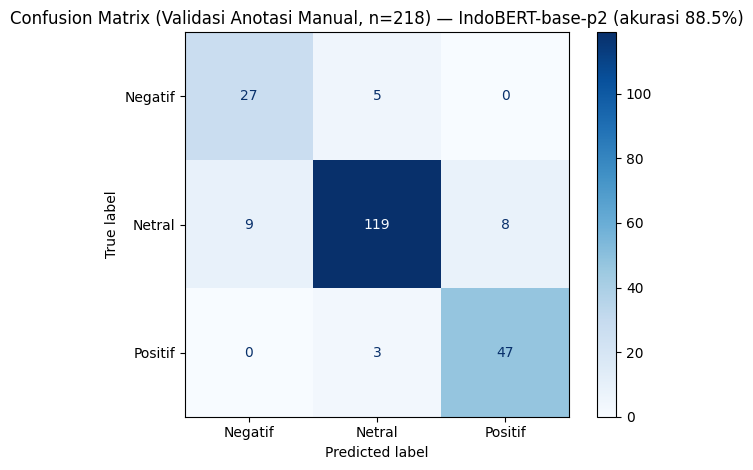

Saved: E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\02_preprocessing\sentimen_indobert\output_sentimen 1\gambar\confusion_matrix_validasi.png


In [7]:
# ════ SEL G : EVALUASI VALIDASI (data anotasi manual, ~20%) ════
from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import numpy as np
import torch

# =========================
# PATH OUTPUT — pakai DIR_OUT & DIR_GAMBAR dari SEL A (tidak di-hardcode ulang)
# =========================
DIR_GAMBAR.mkdir(parents=True, exist_ok=True)


def prediksi_proba(texts, batch=64):
    model.eval()
    out = []

    with torch.no_grad():
        for i in range(0, len(texts), batch):
            enc = tokenizer(
                list(texts[i:i+batch]),
                truncation=True,
                padding=True,
                max_length=MAX_LEN,
                return_tensors='pt'
            ).to(DEVICE)

            logits = model(**enc).logits
            probs = torch.softmax(logits, dim=1)
            out.append(probs.cpu().numpy())

    return np.vstack(out)


proba_va = prediksi_proba(va['Teks'].tolist())
pred_va = proba_va.argmax(axis=1)
y_true = va['label_id'].values

acc = accuracy_score(y_true, pred_va)

print(f'AKURASI VALIDASI: {acc:.4f} ({acc*100:.1f}%)\n')

print(
    classification_report(
        y_true,
        pred_va,
        target_names=['Negatif', 'Netral', 'Positif']
    )
)

cm = confusion_matrix(y_true, pred_va)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Negatif', 'Netral', 'Positif']
).plot(cmap='Blues')

plt.title(
    f'Confusion Matrix (Validasi Anotasi Manual, n={len(y_true)}) — '
    f'IndoBERT-base-p2 (akurasi {acc*100:.1f}%)'
)
plt.tight_layout()

PATH_CM = DIR_GAMBAR / 'confusion_matrix_validasi.png'
plt.savefig(PATH_CM, dpi=150, bbox_inches='tight')
plt.show()

print("Saved:", PATH_CM)

## 🎯 SEL H — Prediksi Skor Sentimen SEMUA Artikel (X2)

In [8]:
# ════ SEL H : PREDIKSI X2 SEMUA ARTIKEL ════
proba_all=prediksi_proba(df_berita['Teks'].tolist())
p_neg,p_net,p_pos=proba_all[:,0],proba_all[:,1],proba_all[:,2]
df_hasil=df_berita.copy()
df_hasil['P_Negatif']=p_neg.round(4); df_hasil['P_Netral']=p_net.round(4); df_hasil['P_Positif']=p_pos.round(4)
df_hasil['Skor_Sentimen']=(p_pos-p_neg).round(4)              # X2 kontinu [-1,1]
df_hasil['Confidence']=proba_all.max(1).round(4)
df_hasil['Label_Sentimen']=pd.Series(proba_all.argmax(1)).map(ID2LABEL).values
df_hasil['Sentimen_Diskrit']=df_hasil['Label_Sentimen'].map({'Positif':1,'Netral':0,'Negatif':-1})
df_hasil.to_csv(DIR_OUT/'skor_sentimen_per_artikel.csv',index=False,encoding='utf-8-sig')
print('💾 skor_sentimen_per_artikel.csv'); print(df_hasil['Label_Sentimen'].value_counts().to_string())
print(f'Skor: mean={df_hasil["Skor_Sentimen"].mean():+.3f} std={df_hasil["Skor_Sentimen"].std():.3f}')

💾 skor_sentimen_per_artikel.csv
Label_Sentimen
Netral     5840
Positif    2638
Negatif     802
Skor: mean=+0.198 std=0.557


## 🧩 SEL I — Matriks Kesesuaian SELURUH Artikel (N=9.280) → Gambar 4.x

Membandingkan **prediksi IndoBERT** (`Label_Sentimen`) terhadap **auto-label leksikon** (`Label_Auto`) pada seluruh korpus berita.

> ⚠️ **Catatan metodologis (penting untuk Bab 4):** seluruh 9.280 artikel tidak memiliki label manual sebagai *ground truth*, sehingga matriks ini merupakan **matriks kesesuaian (*agreement matrix*)** antara dua metode pelabelan otomatis — bukan pengukuran akurasi absolut. Auto-label leksikon bersifat indikatif dan dapat mengandung kesalahan, sehingga tingkat kesesuaian mengukur konsistensi antarmetode, bukan kebenaran model. Evaluasi akurasi resmi model tetap mengacu pada SEL G (validasi anotasi manual, n = 218). Statistik pendukung: persentase kesesuaian (*agreement*) sebesar 89,9% dan nilai *Cohen's Kappa* 0,8019.

Total artikel        : 9,280
Kesesuaian (agreement): 0.8960 (89.6%)
Cohen's Kappa        : 0.7980

Classification report (referensi = Auto-Label leksikon — bersifat indikatif, bukan ground truth):
              precision    recall  f1-score   support

     Negatif       0.78      0.71      0.75       883
      Netral       0.93      0.92      0.92      5914
     Positif       0.86      0.92      0.89      2483

    accuracy                           0.90      9280
   macro avg       0.86      0.85      0.85      9280
weighted avg       0.90      0.90      0.90      9280



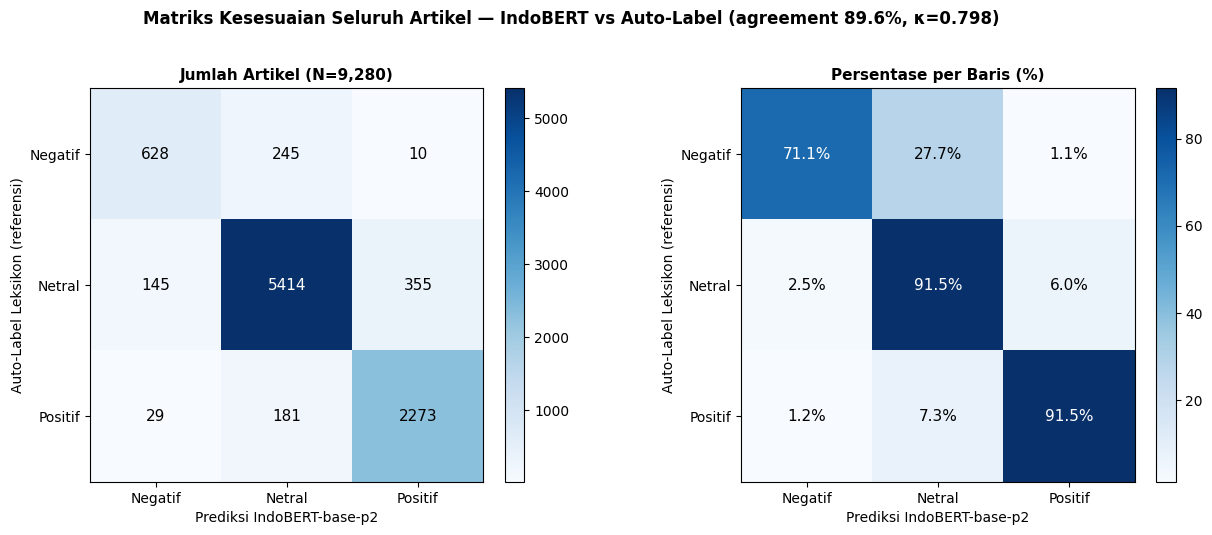

Saved: E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\02_preprocessing\sentimen_indobert\output_sentimen 1\gambar\confusion_matrix_seluruh_artikel.png
Saved: E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\02_preprocessing\sentimen_indobert\output_sentimen 1\tabel_confusion_matrix_seluruh_artikel.csv


In [9]:
# ════ SEL I : CONFUSION MATRIX SELURUH ARTIKEL (IndoBERT vs Auto-Label) ════
from sklearn.metrics import confusion_matrix, cohen_kappa_score, classification_report
import matplotlib.pyplot as plt
import numpy as np

LABELS = ['Negatif', 'Netral', 'Positif']

# ── Pastikan kolom tersedia (Label_Auto dibuat di SEL C, terbawa ke df_hasil) ──
if 'Label_Auto' not in df_hasil.columns:
    print('Kolom Label_Auto belum ada di df_hasil — menghitung ulang dari SEL C...')
    df_hasil['Label_Auto'] = df_hasil['Teks'].apply(auto_label)

y_ref  = df_hasil['Label_Auto'].values        # referensi: leksikon (SEL C)
y_pred = df_hasil['Label_Sentimen'].values    # prediksi : IndoBERT fine-tuned (SEL H)
N = len(df_hasil)

# ── Statistik kesesuaian ──
agree = (y_ref == y_pred).mean()
kappa = cohen_kappa_score(y_ref, y_pred, labels=LABELS)
print(f'Total artikel        : {N:,}')
print(f'Kesesuaian (agreement): {agree:.4f} ({agree*100:.1f}%)')
print(f"Cohen's Kappa        : {kappa:.4f}")
print()
print('Classification report (referensi = Auto-Label leksikon — bersifat indikatif, bukan ground truth):')
print(classification_report(y_ref, y_pred, labels=LABELS, zero_division=0))

# ── Confusion matrix: hitungan absolut & normalisasi per-baris ──
cm_abs  = confusion_matrix(y_ref, y_pred, labels=LABELS)
cm_norm = cm_abs / cm_abs.sum(axis=1, keepdims=True) * 100  # % per baris referensi

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))

for ax, mat, judul, fmt in [
    (axes[0], cm_abs,  f'Jumlah Artikel (N={N:,})', 'd'),
    (axes[1], cm_norm, 'Persentase per Baris (%)',  '.1f'),
]:
    im = ax.imshow(mat, cmap='Blues')
    ax.set_xticks(range(3)); ax.set_xticklabels(LABELS)
    ax.set_yticks(range(3)); ax.set_yticklabels(LABELS)
    ax.set_xlabel('Prediksi IndoBERT-base-p2')
    ax.set_ylabel('Auto-Label Leksikon (referensi)')
    ax.set_title(judul, fontweight='bold', fontsize=11)
    thresh = mat.max() / 2
    for r in range(3):
        for c in range(3):
            val = mat[r, c]
            teks = f'{val:{fmt}}' + ('%' if fmt != 'd' else '')
            ax.text(c, r, teks, ha='center', va='center',
                    color='white' if val > thresh else 'black', fontsize=11)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

fig.suptitle(
    f'Matriks Kesesuaian Seluruh Artikel — IndoBERT vs Auto-Label '
    f'(agreement {agree*100:.1f}%, κ={kappa:.3f})',
    fontweight='bold', fontsize=12, y=1.02
)
plt.tight_layout()

PATH_CM_ALL = DIR_GAMBAR / 'confusion_matrix_seluruh_artikel.png'
plt.savefig(PATH_CM_ALL, dpi=150, bbox_inches='tight')
plt.show()
print('Saved:', PATH_CM_ALL)

# ── Simpan tabel CSV untuk lampiran Bab 4 ──
import pandas as pd
df_cm = pd.DataFrame(cm_abs, index=[f'Ref_{l}' for l in LABELS],
                     columns=[f'Pred_{l}' for l in LABELS])
df_cm['Total_Ref'] = df_cm.sum(axis=1)
df_cm.to_csv(DIR_TABLE / 'tabel_confusion_matrix_seluruh_artikel.csv', encoding='utf-8-sig')
print('Saved:', DIR_TABLE / 'tabel_confusion_matrix_seluruh_artikel.csv')


## 📊 SEL J — Distribusi Sentimen per Emiten → Tabel 4.x

Label_Sentimen  Positif  Netral  Negatif  Total  % Positif  % Netral  % Negatif
Kode_Emiten                                                                    
ADRO                656     966      215   1837       35.7      52.6       11.7
ADMR                140     169       56    365       38.4      46.3       15.3
ITMG                261     285      105    651       40.1      43.8       16.1
PTBA                488    1274      126   1888       25.8      67.5        6.7
MEDC                423     863      112   1398       30.3      61.7        8.0
AKRA                287     470       73    830       34.6      56.6        8.8
PGAS                383    1813      115   2311       16.6      78.5        5.0


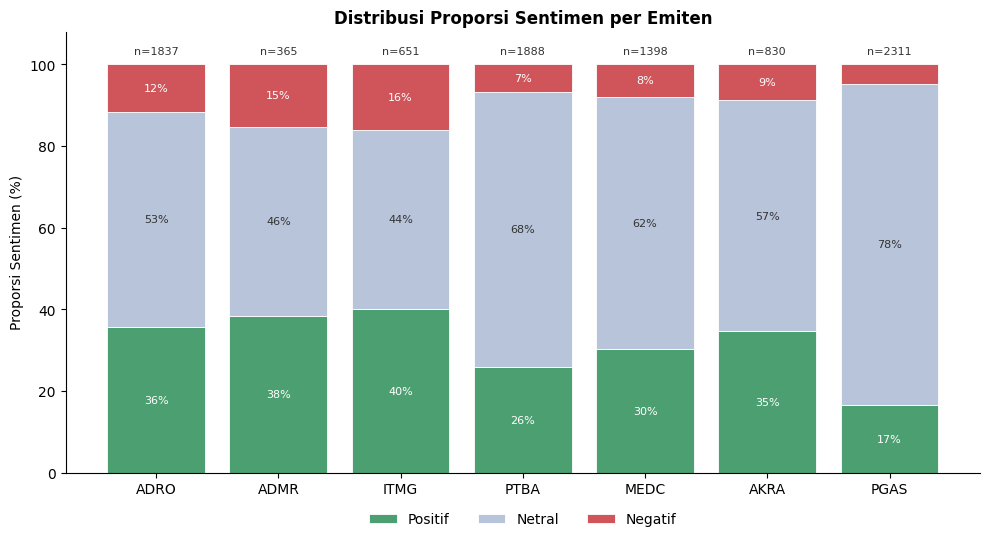

In [15]:
# ════ SEL J : DISTRIBUSI PROPORSI SENTIMEN PER EMITEN ════
kolom_wajib = ['Kode_Emiten', 'Label_Sentimen', 'Headline']
missing = [c for c in kolom_wajib if c not in df_hasil.columns]
if missing:
    raise ValueError(f'Kolom tidak ditemukan: {missing}')

# --- pivot jumlah artikel per kelas ---
pivot_dist = pd.pivot_table(
    df_hasil, index='Kode_Emiten', columns='Label_Sentimen',
    values='Headline', aggfunc='count', fill_value=0
).reindex(URUTAN_EMITEN, fill_value=0)

for col in ['Positif', 'Netral', 'Negatif']:
    if col not in pivot_dist.columns:
        pivot_dist[col] = 0
pivot_dist = pivot_dist[['Positif', 'Netral', 'Negatif']]
pivot_dist['Total'] = pivot_dist.sum(axis=1)

# --- proporsi (%) ---
for c in ['Positif', 'Netral', 'Negatif']:
    pivot_dist[f'% {c}'] = np.where(
        pivot_dist['Total'] > 0,
        (pivot_dist[c] / pivot_dist['Total'] * 100).round(1), 0)

print(pivot_dist.to_string())
pivot_dist.to_csv(DIR_TABLE / 'tabel_distribusi_sentimen_per_emiten.csv',
                  encoding='utf-8-sig')

# =========================
# PLOT — STACKED 100% + jumlah artikel
# =========================
total = pivot_dist['Total'].values
p = pivot_dist['% Positif'].values
n = pivot_dist['% Netral'].values
g = pivot_dist['% Negatif'].values
x = np.arange(len(pivot_dist))

c_pos, c_net, c_neg = '#4c9f70', '#b8c4d9', '#d0555a'

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.bar(x, p, color=c_pos, label='Positif', edgecolor='white', linewidth=0.6)
ax.bar(x, n, bottom=p, color=c_net, label='Netral', edgecolor='white', linewidth=0.6)
ax.bar(x, g, bottom=p + n, color=c_neg, label='Negatif', edgecolor='white', linewidth=0.6)

# label persentase di dalam batang
for i in range(len(x)):
    if p[i] > 6: ax.text(i, p[i]/2, f'{p[i]:.0f}%', ha='center', va='center', fontsize=8, color='white')
    if n[i] > 6: ax.text(i, p[i]+n[i]/2, f'{n[i]:.0f}%', ha='center', va='center', fontsize=8, color='#333')
    if g[i] > 6: ax.text(i, p[i]+n[i]+g[i]/2, f'{g[i]:.0f}%', ha='center', va='center', fontsize=8, color='white')

# jumlah artikel di atas batang
for i in range(len(x)):
    ax.text(i, 102, f'n={int(total[i])}', ha='center', va='bottom', fontsize=8, color='#333')

ax.set_xticks(x)
ax.set_xticklabels(pivot_dist.index)
ax.set_ylabel('Proporsi Sentimen (%)')
ax.set_ylim(0, 108)
ax.set_title('Distribusi Proporsi Sentimen per Emiten', fontweight='bold')
ax.legend(loc='lower center', bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=False)
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig(DIR_IMG / 'distribusi_sentimen_per_emiten.png', dpi=150, bbox_inches='tight')
plt.show()

## 📅 SEL K — Agregasi Skor Sentimen Harian (+ forward-fill)

In [13]:
# ════ SEL K : AGREGASI HARIAN (REVISI AUDIT) ════
df_hasil['Tanggal']=pd.to_datetime(df_hasil['Tanggal'],errors='coerce')
df_agg=(df_hasil.groupby(['Kode_Emiten','Tanggal'])
    .agg(Skor_Sentimen=('Skor_Sentimen','mean'),
         Skor_Sentimen_Std=('Skor_Sentimen','std'),
         Confidence_Mean=('Confidence','mean'),
         Jumlah_Artikel=('Skor_Sentimen','count'),
         N_Positif=('Label_Sentimen',lambda x:(x=='Positif').sum()),
         N_Negatif=('Label_Sentimen',lambda x:(x=='Negatif').sum()),
         N_Netral =('Label_Sentimen',lambda x:(x=='Netral').sum()))
    .reset_index())
df_agg['Skor_Sentimen_Std']=df_agg['Skor_Sentimen_Std'].fillna(0)
df_agg['Skor_Sentimen']=df_agg['Skor_Sentimen'].round(4); df_agg['Ada_Berita']=1

# ── FIX AUDIT #1: pakai kalender hari bursa ASLI dari technical_features.csv
# (PREP_01) kalau tersedia — supaya tanggal 100% sinkron saat merge X1+X2.
# Fallback ke bdate_range generik kalau file belum ada (mis. urutan eksekusi
# PREP_02 sebelum PREP_01).
PATH_TEKNIKAL = DIR_PROCESSED / 'technical_features.csv'
if PATH_TEKNIKAL.exists():
    _tgl_teknikal = pd.read_csv(PATH_TEKNIKAL, usecols=['Date'])['Date']
    hari = pd.to_datetime(sorted(_tgl_teknikal.unique()))
    print(f'  ℹ️  Kalender hari bursa dipakai dari technical_features.csv '
          f'({len(hari)} hari, {hari.min().date()} → {hari.max().date()})')
else:
    hari = pd.bdate_range(df_agg['Tanggal'].min(), df_agg['Tanggal'].max())
    print(f'  ⚠️  technical_features.csv belum ada — fallback ke bdate_range '
          f'generik ({len(hari)} hari). Jalankan ulang SEL K setelah PREP_01 '
          f'selesai supaya kalender 100% sinkron.')

idx=pd.MultiIndex.from_product([URUTAN_EMITEN,hari],names=['Kode_Emiten','Tanggal'])
df_full=pd.DataFrame(index=idx).reset_index().merge(df_agg,on=['Kode_Emiten','Tanggal'],how='left')
df_full['Ada_Berita']=df_full['Ada_Berita'].fillna(0).astype(int)
df_full=df_full.sort_values(['Kode_Emiten','Tanggal'])
df_full['Skor_Sentimen']=df_full.groupby('Kode_Emiten')['Skor_Sentimen'].ffill().fillna(0.0)

# ── FIX AUDIT #2: Skor_Sentimen_Std (dispersi/ketidaksepakatan opini pasar)
# TETAP dipertahankan — forward-fill sejalan dengan Skor_Sentimen, bukan
# dibuang sebelum export seperti versi sebelumnya.
df_full['Skor_Sentimen_Std']=df_full.groupby('Kode_Emiten')['Skor_Sentimen_Std'].ffill().fillna(0.0)

for c in ['Jumlah_Artikel','N_Positif','N_Negatif','N_Netral']:
    df_full[c]=df_full[c].fillna(0).astype(int)
df_full['Skor_Sentimen_Mean']=df_full['Skor_Sentimen']
print('Total hari-emiten:',len(df_full)); print(df_full.head(8).to_string(index=False))

  ℹ️  Kalender hari bursa dipakai dari technical_features.csv (1074 hari, 2022-01-03 → 2026-06-30)
Total hari-emiten: 7518
Kode_Emiten    Tanggal  Skor_Sentimen  Skor_Sentimen_Std  Confidence_Mean  Jumlah_Artikel  N_Positif  N_Negatif  N_Netral  Ada_Berita  Skor_Sentimen_Mean
       ADMR 2022-01-03         0.9860           0.001697          0.98695               2          2          0         0           1              0.9860
       ADMR 2022-01-04         0.4972           0.706683          0.99410               2          1          0         1           1              0.4972
       ADMR 2022-01-05         0.4972           0.706683              NaN               0          0          0         0           0              0.4972
       ADMR 2022-01-06         0.4972           0.706683              NaN               0          0          0         0           0              0.4972
       ADMR 2022-01-07         0.4972           0.706683              NaN               0          0       

## 📈 SEL L — Visualisasi Tren Sentimen Harian → Gambar 4.x

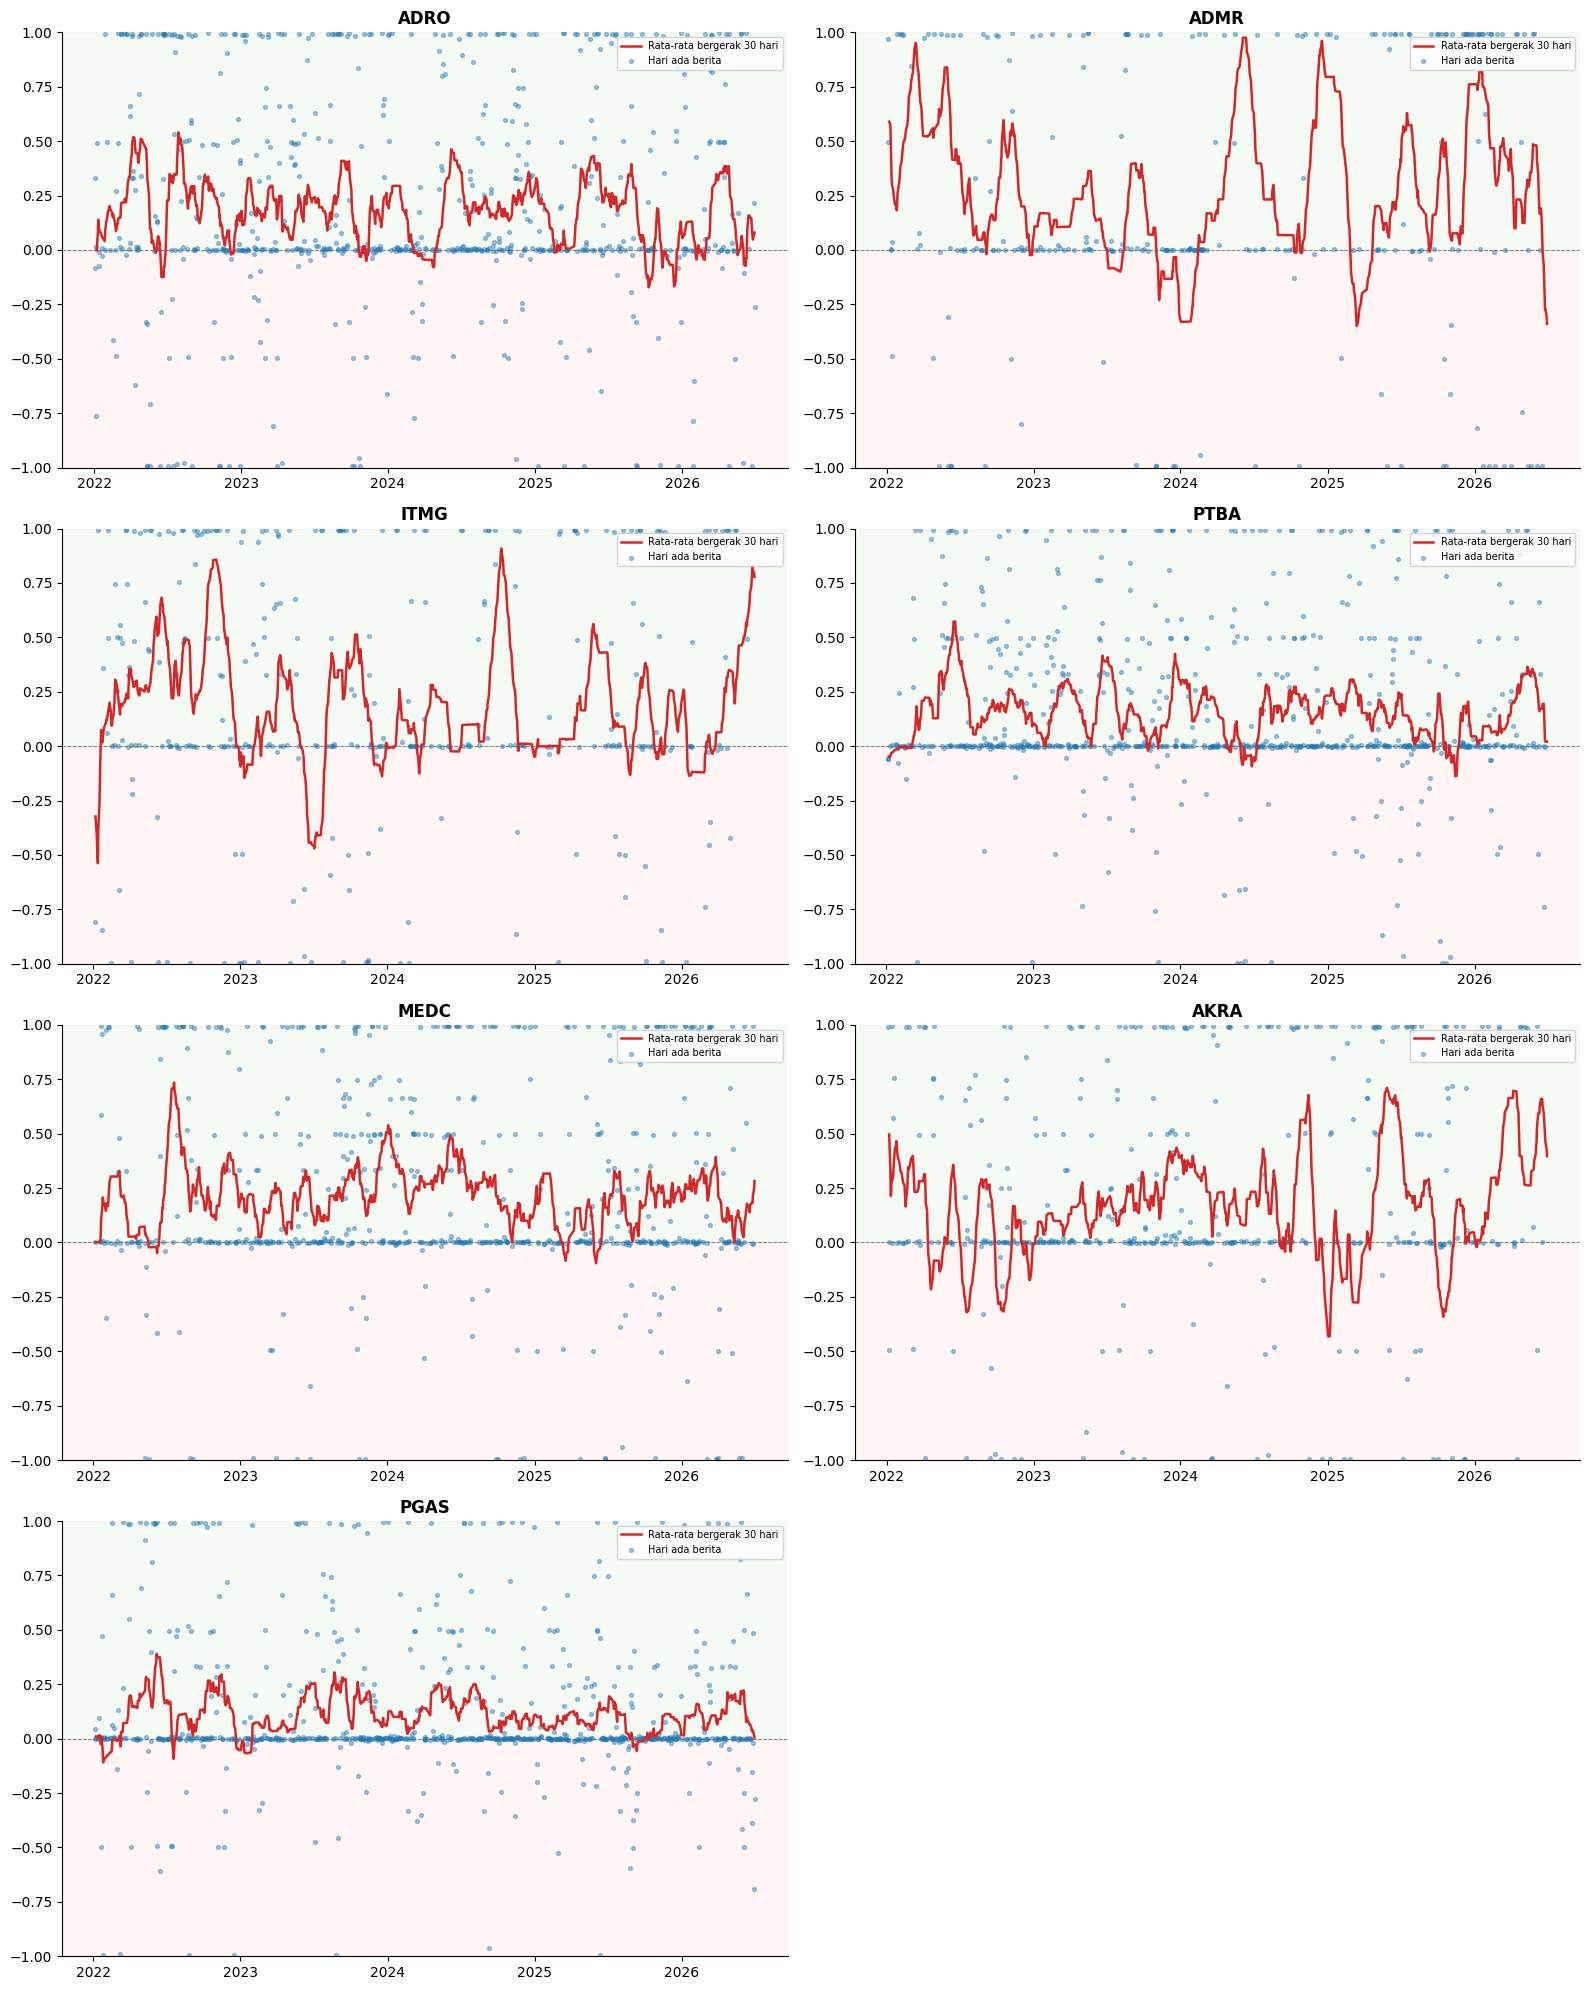

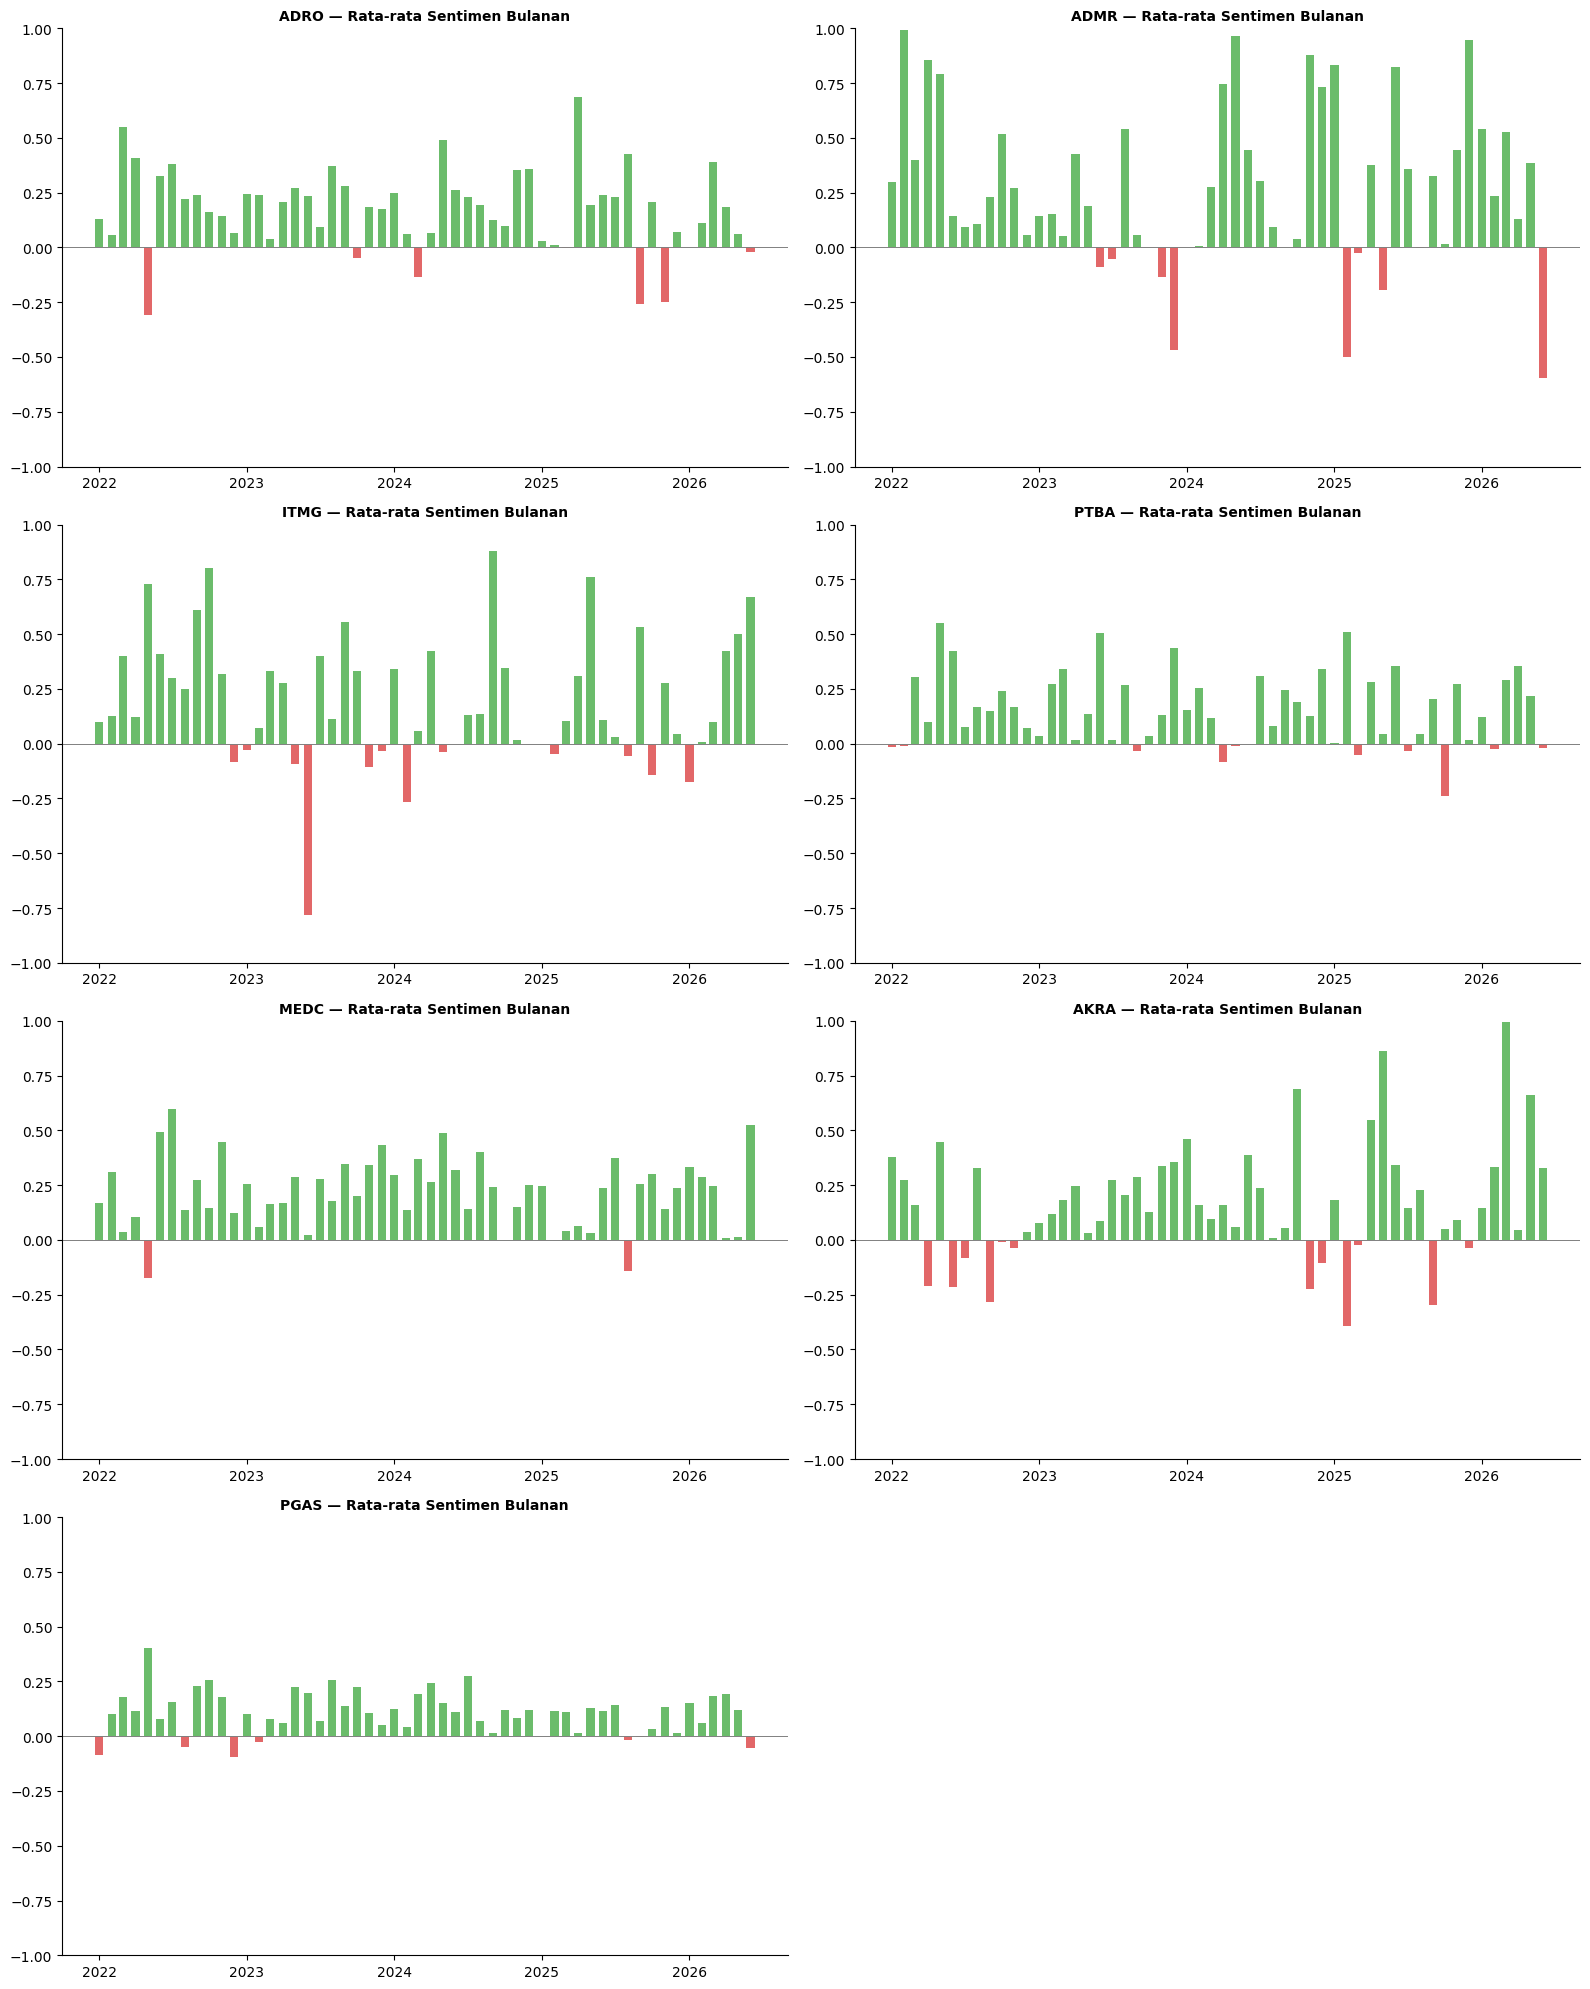

Tersimpan: tren_sentimen_harian.png & tren_sentimen_bulanan.png


In [ ]:
# ════ SEL L : TREN SENTIMEN HARIAN & BULANAN ════
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# ── Tren sentimen harian per emiten (MA30 + hari ada berita) ──
fig, axes = plt.subplots(4, 2, figsize=(16, 20))
axes = axes.flatten()

for i, em in enumerate(URUTAN_EMITEN):
    g = df_full[df_full['Kode_Emiten'] == em].set_index('Tanggal')
    ax = axes[i]

    ax.plot(g.index, g['Skor_Sentimen'].rolling(30, min_periods=5).mean(),
            lw=1.8, color='#d62728', label='Rata-rata bergerak 30 hari', zorder=3)

    hari_berita = g[g['Ada_Berita'] == 1] if 'Ada_Berita' in g.columns else g
    ax.scatter(hari_berita.index, hari_berita['Skor_Sentimen'],
               s=8, color='#1f77b4', alpha=0.4, label='Hari ada berita', zorder=2)

    ax.axhspan(0, 1, color='green', alpha=0.04)
    ax.axhspan(-1, 0, color='red', alpha=0.04)
    ax.axhline(0, color='gray', ls='--', lw=0.7, zorder=1)

    ax.set_title(em, fontweight='bold')
    ax.set_ylim(-1, 1)
    ax.legend(fontsize=7, loc='upper right')
    ax.spines[['top', 'right']].set_visible(False)
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

for j in range(len(URUTAN_EMITEN), len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.savefig(DIR_GAMBAR / 'tren_sentimen_harian.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Rata-rata sentimen bulanan per emiten ──
fig, axes = plt.subplots(4, 2, figsize=(16, 20))
axes = axes.flatten()

for i, em in enumerate(URUTAN_EMITEN):
    g = df_full[df_full['Kode_Emiten'] == em].copy()
    g['Bulan'] = pd.to_datetime(g['Tanggal']).dt.to_period('M')

    agg = g.groupby('Bulan').agg(Sentimen=('Skor_Sentimen', 'mean')).reset_index()
    agg['Bulan'] = agg['Bulan'].dt.to_timestamp()

    ax = axes[i]
    warna = ['#2ca02c' if v >= 0 else '#d62728' for v in agg['Sentimen']]
    ax.bar(agg['Bulan'], agg['Sentimen'], width=20, color=warna, alpha=0.7)
    ax.axhline(0, color='gray', lw=0.7)
    ax.set_title(f'{em} — Rata-rata Sentimen Bulanan', fontweight='bold', fontsize=10)
    ax.set_ylim(-1, 1)
    ax.spines[['top', 'right']].set_visible(False)
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

for j in range(len(URUTAN_EMITEN), len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.savefig(DIR_GAMBAR / 'tren_sentimen_bulanan.png', dpi=150, bbox_inches='tight')
plt.show()

print('Tersimpan: tren_sentimen_harian.png & tren_sentimen_bulanan.png')

Interpretasi Utama

1. Garis merah mayoritas di atas nol (zona hijau).
Untuk hampir semua emiten, rata-rata bergerak 30 hari berada di area positif. Ini konsisten dengan temuan sebelumnya: sentimen berita sektor energi cenderung positif (skor rata-rata +0,190). Pemberitaan didominasi kabar netral-positif, bukan negatif.

2. Titik biru tersebar dari −1 sampai +1.
Skor harian sangat bervariasi — ada hari sangat positif (+1) dan sangat negatif (−1). Ini terjadi pada hari dengan sedikit berita: kalau satu hari cuma ada 1 artikel dan artikel itu negatif, skor harian = −1. Variasi ekstrem ini wajar untuk data sentimen harian.

3. Titik biru menumpuk di sekitar nol (garis netral).
Perhatikan banyak titik biru berkumpul di garis 0. Ini karena mayoritas berita netral (64,3% dari klasifikasi). Hari-hari dengan berita netral menghasilkan skor mendekati nol.

Perbedaan Antaremiten

ADMR — paling fluktuatif. Garis merahnya naik-turun paling tajam (dari −0,35 sampai +0,95). Ini konsisten dengan karakteristik ADMR yang paling bergejolak di seluruh analisis Anda (momentum, volatilitas). Sentimen beritanya pun paling bervariasi.

PGAS — paling stabil dan rendah. Garis merahnya paling datar dan dekat nol (rata-rata 0,11, terendah). Sebagai emiten dengan berita terbanyak (2.311 artikel), sentimennya paling "teredam" — banyak berita membuat rata-rata lebih stabil.

ITMG — ada lonjakan tajam. Terlihat spike ke +0,90 di sekitar akhir 2024. Menandakan periode pemberitaan sangat positif.

## 💾 SEL M — Simpan X2 Harian + Quality Check

In [ ]:
# ════ SEL M : SIMPAN + STATISTIK FITUR SENTIMEN HARIAN ════
df_final = df_full[[
    'Kode_Emiten', 'Tanggal', 'Skor_Sentimen', 'Skor_Sentimen_Std',
    'Jumlah_Artikel', 'Ada_Berita'
]].copy()

df_final = df_final.rename(columns={
    'Kode_Emiten': 'Emiten',
    'Tanggal': 'Date',
    'Skor_Sentimen': 'Sentiment_Mean',
    'Skor_Sentimen_Std': 'Sentiment_Dispersion',
    'Jumlah_Artikel': 'News_Count',
})

df_final['Date'] = pd.to_datetime(df_final['Date'])
df_final = df_final.sort_values(['Emiten', 'Date']).reset_index(drop=True)

path_final = DIR_PROCESSED / 'skor_sentimen_harian.csv'
df_final.to_csv(path_final, index=False, encoding='utf-8-sig')
print(f'{path_final}  ({len(df_final):,} baris)')
print(f'Kolom: {df_final.columns.tolist()}')

# ── Statistik agregat 4 fitur X2 ──
print('\n' + '='*70)
print('  STATISTIK AGREGAT 4 FITUR SENTIMEN (X2)')
print('='*70)
tabel = (df_final[['Sentiment_Mean', 'Sentiment_Dispersion', 'News_Count', 'Ada_Berita']]
         .describe().T[['mean', 'std', 'min', 'max']].round(4))
tabel.columns = ['Mean', 'Std', 'Min', 'Maks']
print(tabel.to_string())

# ── Cakupan data harian ──
print('\n' + '='*70)
print('  CAKUPAN DATA HARIAN')
print('='*70)
n_total = len(df_final)
n_ada = int(df_final['Ada_Berita'].sum())
print(f'  Total baris harian       : {n_total:,}')
print(f'  Hari ada berita          : {n_ada:,} ({n_ada/n_total*100:.1f}%)')
print(f'  Hari tanpa berita        : {n_total-n_ada:,} ({(n_total-n_ada)/n_total*100:.1f}%)')
print(f'  Rata-rata berita per hari: {df_final.loc[df_final["Ada_Berita"]==1, "News_Count"].mean():.2f}')
print(f'  Maks berita satu hari    : {int(df_final["News_Count"].max())}')

# ── Quality check ──
print('\n' + '='*70)
print('  QUALITY CHECK')
print('='*70)
print('  Missing :', df_final.isnull().sum().sum(), '| Duplikat:', df_final.duplicated().sum())
print('  Range tgl:', df_final['Date'].min().date(), '->', df_final['Date'].max().date())

E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\processed\skor_sentimen_harian.csv  (7,518 baris)
Kolom: ['Emiten', 'Date', 'Sentiment_Mean', 'Sentiment_Dispersion', 'News_Count', 'Ada_Berita']

  STATISTIK AGREGAT 4 FITUR SENTIMEN (X2)
                        Mean     Std     Min     Maks
Sentiment_Mean        0.1824  0.4994 -0.9954   0.9955
Sentiment_Dispersion  0.1382  0.2767  0.0000   1.4069
News_Count            1.0908  1.7023  0.0000  20.0000
Ada_Berita            0.4976  0.5000  0.0000   1.0000

  CAKUPAN DATA HARIAN
  Total baris harian       : 7,518
  Hari ada berita          : 3,741 (49.8%)
  Hari tanpa berita        : 3,777 (50.2%)
  Rata-rata berita per hari: 2.19
  Maks berita satu hari    : 20

  QUALITY CHECK
  Missing : 0 | Duplikat: 0
  Range tgl: 2022-01-03 -> 2026-06-30


## 📦 SEL N — Export Final (siap merge dengan Y & X1)

In [ ]:
 # ════ SEL N : EXPORT UNTUK MERGE ════
df_final.to_csv(DIR_PROCESSED/'sentiment_ready_for_merge.csv', index=False, encoding='utf-8-sig')
print('sentiment_ready_for_merge.csv tersimpan')
print(f'Kolom kunci merge : Emiten, Date')
print(f'Kolom fitur X2    : Sentiment_Mean, Sentiment_Dispersion, News_Count, Ada_Berita')
print(f'Jumlah baris      : {len(df_final):,}')

sentiment_ready_for_merge.csv tersimpan
Kolom kunci merge : Emiten, Date
Kolom fitur X2    : Sentiment_Mean, Sentiment_Dispersion, News_Count, Ada_Berita
Jumlah baris      : 7,518
